# Optimizers

Optimizer determine how a neural networks updates its weights and biases to minimize the loss function during training.


## Training process follows.

1. Forward Propagation
2. Calculate loss
3. Backpropagation
4. Optimizer updates parameters

Repeat the process untill loss become minimum.


## Types of optimizers

- Batch Gradient Descent
- Stochastic Gradient Descent (SGD)
- SGD with momentum
- Adagrad
- RMSprop
- Adam



## Batch Gradient

Uses the entire training dataset to calculate each gradient update.

## Stochastic Gradient Descent(SGD)

Updates parameters using one training example at a time.

## SGD with momentum

Uses previous updates to build momentum and reduce zigzagging.

## Adagrad

Adapts the effective learning rate separately for each parameter.

## RMSprop

Uses a moving average of squared gradients to adapt parameter updates.

## Adam

Combines momentum-like first-moment estimates with adaptive second-moment estimates.

In [1]:
import tensorflow as tf

import numpy as np

(x_train,y_train),(x_test,y_test) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [4]:
X_train = x_train.astype("float32") / 255.0
X_test = x_test.astype("float32") / 255.0

In [7]:
model = tf.keras.Sequential(
    [
        tf.keras.Input(shape=(28,28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128,activation="relu"),
        tf.keras.layers.Dense(10,activation='softmax')
    ]
)

In [9]:
# SGD optimizer

optimizer = tf.keras.optimizers.SGD(learning_rate=0.01)

In [10]:
model.compile(
    optimizer = optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [11]:
history = model.fit(X_train,y_train,batch_size=128,epochs=10,verbose=2,validation_split=0.1)

Epoch 1/10
422/422 - 2s - 5ms/step - accuracy: 0.7231 - loss: 1.2296 - val_accuracy: 0.8743 - val_loss: 0.6323
Epoch 2/10
422/422 - 2s - 4ms/step - accuracy: 0.8598 - loss: 0.5839 - val_accuracy: 0.8997 - val_loss: 0.4265
Epoch 3/10
422/422 - 2s - 4ms/step - accuracy: 0.8793 - loss: 0.4621 - val_accuracy: 0.9100 - val_loss: 0.3574
Epoch 4/10
422/422 - 2s - 4ms/step - accuracy: 0.8899 - loss: 0.4076 - val_accuracy: 0.9150 - val_loss: 0.3203
Epoch 5/10
422/422 - 3s - 7ms/step - accuracy: 0.8971 - loss: 0.3748 - val_accuracy: 0.9195 - val_loss: 0.2978
Epoch 6/10
422/422 - 2s - 4ms/step - accuracy: 0.9024 - loss: 0.3519 - val_accuracy: 0.9227 - val_loss: 0.2813
Epoch 7/10
422/422 - 2s - 4ms/step - accuracy: 0.9065 - loss: 0.3346 - val_accuracy: 0.9257 - val_loss: 0.2679
Epoch 8/10
422/422 - 2s - 4ms/step - accuracy: 0.9098 - loss: 0.3205 - val_accuracy: 0.9288 - val_loss: 0.2578
Epoch 9/10
422/422 - 2s - 4ms/step - accuracy: 0.9128 - loss: 0.3086 - val_accuracy: 0.9308 - val_loss: 0.2499
E

In [12]:
test_loss,test_accuracy = model.evaluate(X_test,y_test,verbose=0)

In [13]:
print(test_loss)
print(test_accuracy)

0.2757909595966339
0.9228000044822693


In [15]:
# SGD with momentum

optimizer = tf.keras.optimizers.SGD(learning_rate=0.01,momentum=0.9)


model.compile(
    optimizer = optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


history = model.fit(X_train,y_train,batch_size=128,epochs=10,verbose=2,validation_split=0.1)

Epoch 1/10
422/422 - 2s - 6ms/step - accuracy: 0.9232 - loss: 0.2701 - val_accuracy: 0.9452 - val_loss: 0.1990
Epoch 2/10
422/422 - 2s - 4ms/step - accuracy: 0.9379 - loss: 0.2203 - val_accuracy: 0.9582 - val_loss: 0.1641
Epoch 3/10
422/422 - 3s - 8ms/step - accuracy: 0.9467 - loss: 0.1879 - val_accuracy: 0.9628 - val_loss: 0.1450
Epoch 4/10
422/422 - 2s - 4ms/step - accuracy: 0.9536 - loss: 0.1639 - val_accuracy: 0.9653 - val_loss: 0.1305
Epoch 5/10
422/422 - 2s - 4ms/step - accuracy: 0.9589 - loss: 0.1456 - val_accuracy: 0.9682 - val_loss: 0.1184
Epoch 6/10
422/422 - 2s - 4ms/step - accuracy: 0.9629 - loss: 0.1312 - val_accuracy: 0.9692 - val_loss: 0.1126
Epoch 7/10
422/422 - 2s - 4ms/step - accuracy: 0.9671 - loss: 0.1193 - val_accuracy: 0.9730 - val_loss: 0.1047
Epoch 8/10
422/422 - 2s - 4ms/step - accuracy: 0.9695 - loss: 0.1095 - val_accuracy: 0.9715 - val_loss: 0.1016
Epoch 9/10
422/422 - 3s - 7ms/step - accuracy: 0.9720 - loss: 0.1011 - val_accuracy: 0.9727 - val_loss: 0.0960
E

In [16]:
test_loss,test_accuracy = model.evaluate(X_test,y_test,verbose=0)
print(test_loss)
print(test_accuracy)

0.10331590473651886
0.9708999991416931


In [17]:
# Adagrad

optimizer = tf.keras.optimizers.Adagrad(learning_rate=0.01)



model.compile(
    optimizer = optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


history = model.fit(X_train,y_train,batch_size=128,epochs=10,verbose=2,validation_split=0.1)

Epoch 1/10
422/422 - 2s - 6ms/step - accuracy: 0.9765 - loss: 0.0856 - val_accuracy: 0.9758 - val_loss: 0.0901
Epoch 2/10
422/422 - 2s - 4ms/step - accuracy: 0.9770 - loss: 0.0837 - val_accuracy: 0.9760 - val_loss: 0.0887
Epoch 3/10
422/422 - 2s - 4ms/step - accuracy: 0.9780 - loss: 0.0818 - val_accuracy: 0.9757 - val_loss: 0.0884
Epoch 4/10
422/422 - 4s - 9ms/step - accuracy: 0.9782 - loss: 0.0801 - val_accuracy: 0.9773 - val_loss: 0.0876
Epoch 5/10
422/422 - 2s - 4ms/step - accuracy: 0.9786 - loss: 0.0786 - val_accuracy: 0.9783 - val_loss: 0.0867
Epoch 6/10
422/422 - 2s - 4ms/step - accuracy: 0.9791 - loss: 0.0770 - val_accuracy: 0.9778 - val_loss: 0.0855
Epoch 7/10
422/422 - 2s - 4ms/step - accuracy: 0.9794 - loss: 0.0756 - val_accuracy: 0.9778 - val_loss: 0.0852
Epoch 8/10
422/422 - 2s - 4ms/step - accuracy: 0.9797 - loss: 0.0742 - val_accuracy: 0.9773 - val_loss: 0.0849
Epoch 9/10
422/422 - 2s - 4ms/step - accuracy: 0.9802 - loss: 0.0729 - val_accuracy: 0.9778 - val_loss: 0.0846
E

In [18]:
test_loss,test_accuracy = model.evaluate(X_test,y_test,verbose=0)
print(test_loss)
print(test_accuracy)

0.09186985343694687
0.9726999998092651


In [19]:
# RMSprop

optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.01)



model.compile(
    optimizer = optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)



history = model.fit(X_train,y_train,batch_size=128,epochs=10,verbose=2,validation_split=0.1)

Epoch 1/10
422/422 - 3s - 6ms/step - accuracy: 0.9360 - loss: 0.2957 - val_accuracy: 0.9520 - val_loss: 0.1581
Epoch 2/10
422/422 - 2s - 4ms/step - accuracy: 0.9642 - loss: 0.1318 - val_accuracy: 0.9752 - val_loss: 0.1042
Epoch 3/10
422/422 - 3s - 7ms/step - accuracy: 0.9734 - loss: 0.1019 - val_accuracy: 0.9702 - val_loss: 0.1197
Epoch 4/10
422/422 - 2s - 6ms/step - accuracy: 0.9773 - loss: 0.0851 - val_accuracy: 0.9712 - val_loss: 0.1363
Epoch 5/10
422/422 - 2s - 4ms/step - accuracy: 0.9801 - loss: 0.0765 - val_accuracy: 0.9695 - val_loss: 0.1663
Epoch 6/10
422/422 - 2s - 4ms/step - accuracy: 0.9824 - loss: 0.0690 - val_accuracy: 0.9753 - val_loss: 0.1509
Epoch 7/10
422/422 - 2s - 4ms/step - accuracy: 0.9848 - loss: 0.0608 - val_accuracy: 0.9782 - val_loss: 0.1445
Epoch 8/10
422/422 - 2s - 4ms/step - accuracy: 0.9860 - loss: 0.0557 - val_accuracy: 0.9697 - val_loss: 0.1962
Epoch 9/10
422/422 - 2s - 5ms/step - accuracy: 0.9883 - loss: 0.0480 - val_accuracy: 0.9752 - val_loss: 0.1679
E

In [20]:
test_loss,test_accuracy = model.evaluate(X_test,y_test,verbose=0)
print(test_loss)
print(test_accuracy)

0.15431877970695496
0.9793999791145325


In [21]:
# Adam

optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)



model.compile(
    optimizer = optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


history = model.fit(X_train,y_train,batch_size=128,epochs=10,verbose=2,validation_split=0.1)

Epoch 1/10
422/422 - 3s - 7ms/step - accuracy: 0.9827 - loss: 0.0810 - val_accuracy: 0.9723 - val_loss: 0.1982
Epoch 2/10
422/422 - 2s - 4ms/step - accuracy: 0.9856 - loss: 0.0636 - val_accuracy: 0.9733 - val_loss: 0.1712
Epoch 3/10
422/422 - 2s - 4ms/step - accuracy: 0.9868 - loss: 0.0602 - val_accuracy: 0.9725 - val_loss: 0.1893
Epoch 4/10
422/422 - 3s - 8ms/step - accuracy: 0.9882 - loss: 0.0467 - val_accuracy: 0.9742 - val_loss: 0.2145
Epoch 5/10
422/422 - 4s - 9ms/step - accuracy: 0.9878 - loss: 0.0510 - val_accuracy: 0.9708 - val_loss: 0.2192
Epoch 6/10
422/422 - 2s - 4ms/step - accuracy: 0.9884 - loss: 0.0524 - val_accuracy: 0.9700 - val_loss: 0.2435
Epoch 7/10
422/422 - 2s - 4ms/step - accuracy: 0.9884 - loss: 0.0514 - val_accuracy: 0.9747 - val_loss: 0.2095
Epoch 8/10
422/422 - 2s - 4ms/step - accuracy: 0.9892 - loss: 0.0442 - val_accuracy: 0.9735 - val_loss: 0.2142
Epoch 9/10
422/422 - 3s - 6ms/step - accuracy: 0.9912 - loss: 0.0350 - val_accuracy: 0.9765 - val_loss: 0.2400
E

In [22]:
test_loss,test_accuracy = model.evaluate(X_test,y_test,verbose=0)
print(test_loss)
print(test_accuracy)

0.22029966115951538
0.9717000126838684


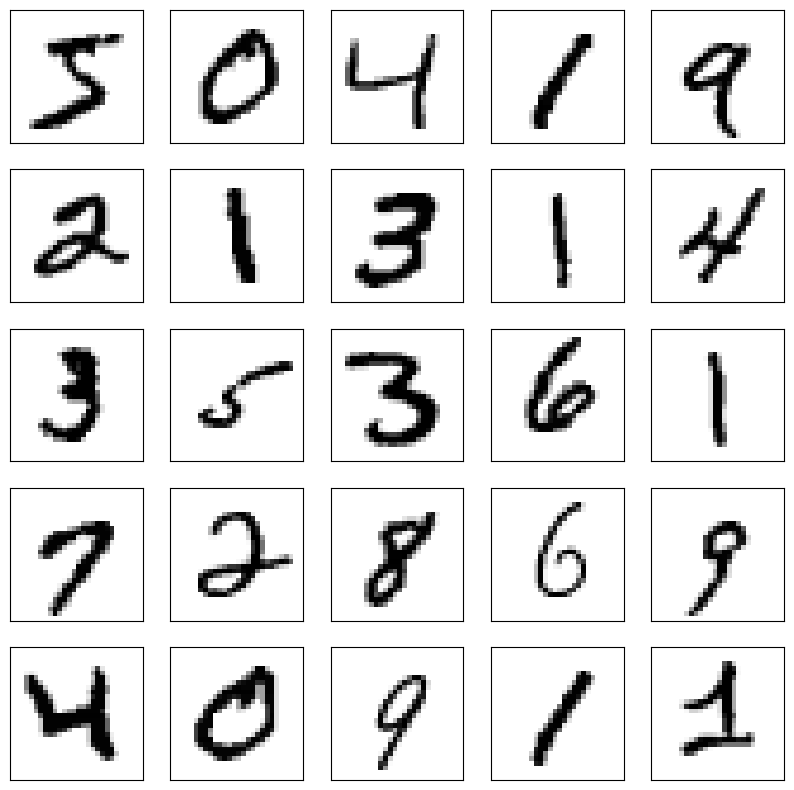

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))

for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i],cmap=plt.cm.binary)